#### Importação das bibliotecas #### 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

#### Carregando o dataset ####

In [3]:
df = pd.read_csv("data/CC GENERAL.csv")

df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


#### Limpeza do dataset #### 

In [8]:
df.shape

(8950, 18)

Checando os valores nulos

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

Das 8.950 linhas do dataset, apenas 14 possuem valores nulos, visto que em relação ao todo é uma quantidade praticamente insignificante, é possível apenas dropá-las sem preenchê-las.

In [12]:
df = df.dropna()

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 8636 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8636 non-null   str    
 1   BALANCE                           8636 non-null   float64
 2   BALANCE_FREQUENCY                 8636 non-null   float64
 3   PURCHASES                         8636 non-null   float64
 4   ONEOFF_PURCHASES                  8636 non-null   float64
 5   INSTALLMENTS_PURCHASES            8636 non-null   float64
 6   CASH_ADVANCE                      8636 non-null   float64
 7   PURCHASES_FREQUENCY               8636 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8636 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8636 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8636 non-null   float64
 11  CASH_ADVANCE_TRX                  8636 non-null   int64  
 12  PURCHASES_TRX         

#### Definindo as features #### 

In [15]:
X = df[['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES',
       'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
       'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY',
       'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
       'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS',
       'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']]

#### Padronização das features #### 

In [16]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Features padronizadas com sucesso!")

Features padronizadas com sucesso!


#### Redução de dimensionalidade #### 

Por eu não saber quantos componentes manter, eu não vou definir o parâmetro quando instanciar o 'PCA'.

In [17]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Análise de Componentes Principais realizada!")

Análise de Componentes Principais realizada!


Manti todos os componentes do dataset então seu formato não mudou.

In [18]:
print(f"Original shape: {X_scaled.shape}")
print(f"Original shape: {X_pca.shape}")

Original shape: (8636, 17)
Original shape: (8636, 17)


Pegando a porcentagem de variância de cada um dos componentes.

In [ ]:
print(f"Porcentagem de variância: {pca.explained_variance_ratio_}")

Porcentagem de variância: [2.72311770e-01 2.03743076e-01 8.91833372e-02 7.57360860e-02
 6.27661816e-02 5.71278613e-02 4.91618788e-02 4.21073427e-02
 3.68169669e-02 3.08150790e-02 2.36380362e-02 1.77453962e-02
 1.42671026e-02 1.17865972e-02 1.00809717e-02 2.71162672e-03
 6.90045972e-07]


Somando todas as variâncias dos componentes.

In [25]:
soma_variancias = pca.explained_variance_ratio_.cumsum()

##### Definindo quantos componentes manter #####

Com o gráfico de linhas é possível ver com quantos componentes conseguimos ter uma quantidade suficiente de informações do nosso dataset.

Queremos encontrar o ponto em que a curva já está bem alta, em torno de 80-90%.

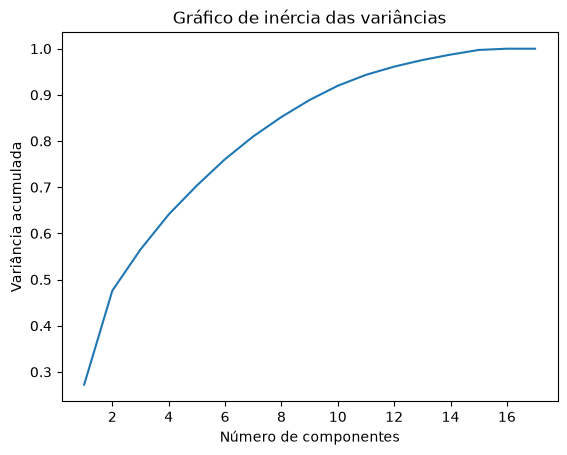

In [30]:
plt.plot([1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17], soma_variancias)
plt.title("Gráfico de inércia das variâncias")
plt.xlabel("Número de componentes")
plt.ylabel("Variância acumulada")
plt.show()

80% começa no ponto de aproximadamente 7 componentes, que será o número escolhido.

##### Análise de componentes com o número de componentes definido #####

In [31]:
pca = PCA(n_components=7)

X_pca = pca.fit_transform(X_scaled)

print("Análise de Componentes Principais realizada!")

Análise de Componentes Principais realizada!


#### Clusterização ####

##### Método do cotovelo #####

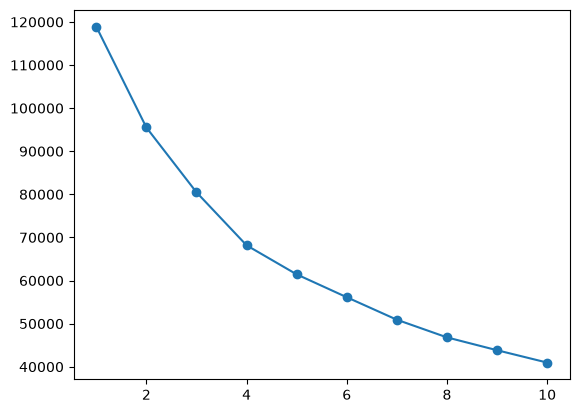

In [32]:
inertias = [] # lista com todas as inércias

for k in range(1, 11): # o limite de clusters será 10
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_pca) # criando os clusters 
    inertias.append(km.inertia_) # adicionando a inércia de cada cluster na lista

plt.plot(range(1,11), inertias, 'o-')

##### Treinamento do modelo #####

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=0, n_init='auto')
cluster_labels = kmeans.fit_predict(X_pca)
kmeans.fit(X_pca) # treinando com as features de dimensões reduzidas

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 7)","[[

##### Plotagem dos clusters ##### 

<Axes: >

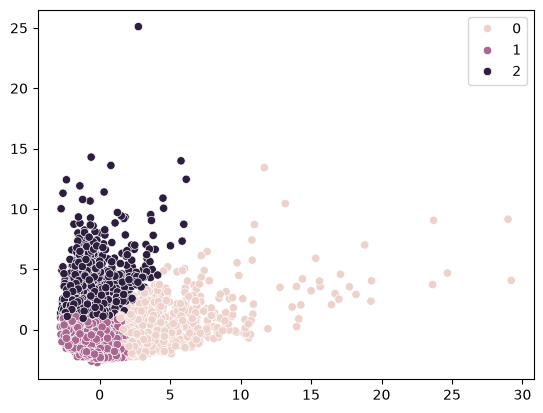

In [48]:
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=kmeans.labels_)

#### Métricas de avaliação ####

As métricas de avaliação são importantes para não avaliarmos os nossos cluster apenas "no olho".

##### Silhouette Score ##### 

Mede, para ponto, o quão bem ele se encaixa no próprio cluster comparado aos clusters vizinhos.

Varia de -1 a 1: quanto mais próximo de 1, melhor (pontos bem agrupados e clusters bem comparados entre si). Perto de 0 significa que os clusters estão se sobrepondo. Negativo significa que pontos provavelmente foram parar no cluster errado.

In [49]:
score = silhouette_score(X_pca, cluster_labels)
print(f"Silhouette Score: {score:.4f}")

Silhouette Score: 0.2799


O resultado deu em um número bem próximo de 0, o que significa que os clusters estão bem sobrepostos.

##### Davies-Bouldin Score ##### 

Mede a razão entre "dispersão de cada cluster" e "distância entre os clusters". 

É o contrário do silhouette: quanto menor (mais perto de 0), melhor, significa clusters compactos e bem separados uns dos outros.

In [50]:
score = davies_bouldin_score(X_pca, cluster_labels)
print(f"Davies-Bouldin Sco: {score:.4f}")

Davies-Bouldin Sco: 1.3678


Resultou em um valor relativamente distante de 0, o que significa clusters bem juntos e descompactos.